# Customer Segmentation with RFM Analysis and K-Means

**Goal:** Group online-store customers into segments based on how recently, how often and how much they buy, so a business can target each group with the right marketing action.

**Data:** Online Retail II dataset: transactions from a UK-based online gift retailer (invoice, product, quantity, price, date, customer and country).

**Approach:**
1. Clean the transaction data
2. Build an RFM table (Recency, Frequency, Monetary value) for each customer
3. Scale the data and use K-Means clustering
4. Choose the number of clusters with the elbow method and silhouette score
5. Name each segment and recommend a business action

**Why it matters:** Not all customers are equally valuable. Segmentation helps a business reward its best customers, win back those who are drifting away and avoid wasting marketing spend.

## 1. Load and inspect the data
First I load the transactions and check the size, the column names and any missing values.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("online_retail_II.csv", encoding="latin-1", parse_dates=["InvoiceDate"])
print(df.shape)
print(df.columns.tolist())
print(df.isna().sum())
df.head()

(1067371, 8)
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


**What the data looks like:** The dataset has **1,067,371 transaction lines** and 8 columns, covering **1 December 2009 to 9 December 2011**. Two columns have missing values: **Customer ID (243,007 rows, about 23%)** and Description (4,382 rows). The missing customer IDs are a problem because those transactions cannot be tied to a customer.

## 2. Data cleaning
Before analysing, I remove records that would distort customer behaviour:
- **Rows without a Customer ID:** these cannot be linked to a customer, so they cannot be segmented.
- **Cancelled orders:** invoice numbers starting with "C" are cancellations.
- **Zero or negative quantities and prices:** returns, adjustments or data errors.
- **Duplicate rows.**

I also create a **Revenue** column (Quantity × Price).

In [2]:
n0 = len(df)
df = df.dropna(subset=["Customer ID"])                     # can't segment unknown customers
df = df[~df["Invoice"].astype(str).str.startswith("C")]    # remove cancellations
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]          # remove returns / bad prices
df = df.drop_duplicates()
df["Customer ID"] = df["Customer ID"].astype(int)
df["Revenue"] = df["Quantity"] * df["Price"]
print(f"Rows: {n0:,} -> {len(df):,}; customers: {df['Customer ID'].nunique():,}")

Rows: 1,067,371 -> 779,425; customers: 5,878


**Cleaning results:** Applying the filters in order removed:
- 243,007 rows with no Customer ID
- 18,744 cancelled orders
- 71 rows with zero or negative quantity or price
- 26,124 duplicate rows

That is **287,946 rows (27%)** in total, leaving **779,425 transaction lines from 5,878 customers** across 36,969 invoices and 41 countries (about 90% of rows are from the United Kingdom).

*Note: removing rows with no Customer ID means the revenue shares later in this notebook describe identified customers only, not guest checkouts.*

## 3. Build the RFM table
RFM is a standard marketing technique that describes each customer with three numbers:
- **Recency:** days since the customer's last purchase (lower is better)
- **Frequency:** number of distinct orders (higher is better)
- **Monetary:** total amount spent (higher is better)

Recency is measured from one day after the last date in the dataset.

In [3]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

rfm.describe().round(1)

,Customer ID,Recency,Frequency,Monetary
count,5878.0,5878.0,5878.0,5878.0
mean,15315.3,201.3,6.3,2955.9
std,1715.6,209.3,13.0,14440.9
min,12346.0,1.0,1.0,3.0
25%,13833.2,26.0,1.0,342.3
50%,15314.5,96.0,3.0,867.7
75%,16797.8,380.0,7.0,2248.3
max,18287.0,739.0,398.0,580987.0


**What the RFM table shows (5,878 customers):**
- **Recency:** ranges from 1 to 739 days, with a median of 96 days. A quarter of customers bought in the last 26 days, and another quarter have been inactive for more than 380 days.
- **Frequency:** the median customer placed 3 orders, and at least a quarter bought only once. The most active customer placed 398 orders.
- **Monetary:** the median customer spent **£868**, but the mean is **£2,956** and the largest customer spent **£580,987**.

Because the mean is much higher than the median for frequency and spend, both are **heavily right-skewed**: a small number of customers account for very large amounts. This is why the log transform is needed before clustering.

## 4. Prepare the data for clustering
K-Means groups customers by distance, so two things matter:
- **Log transform:** spending and frequency are heavily skewed (a few customers buy far more than the rest). A log transform stops those few from dominating.
- **Standard scaling:** puts Recency, Frequency and Monetary on the same scale, so no one variable counts for more just because of its units.

In [5]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])   # tames the skew
X = StandardScaler().fit_transform(rfm_log)

## 5. Choosing the number of segments (K)
There is no single correct number of clusters, so I use two checks:
- **Elbow method:** plots the within-cluster error for different K. The "bend" suggests where extra clusters stop helping much.
- **Silhouette score:** measures how well separated the clusters are (higher is better, maximum 1).

I also consider usability: a business can act on 3-5 segments, but not on 10.

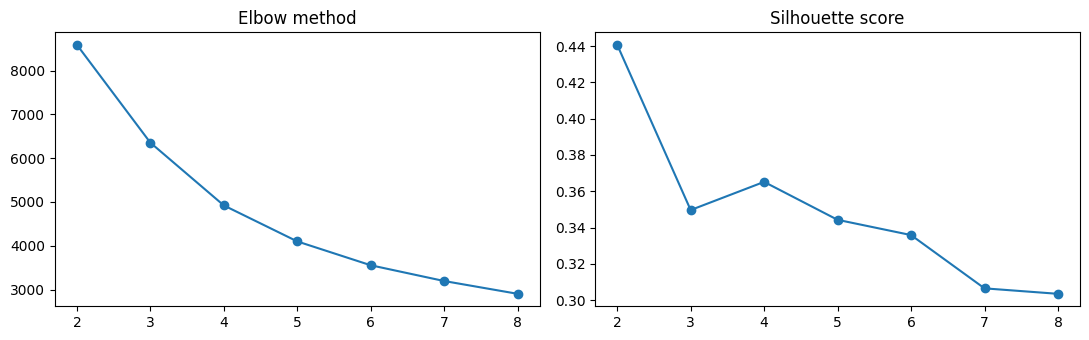

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks, inertia, sil = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=5000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow method")
ax[1].plot(ks, sil, marker="o");     ax[1].set_title("Silhouette score")
plt.tight_layout(); plt.savefig("choose_k.png", dpi=200); plt.show()

**Choosing K = 4:**
- The **elbow curve falls smoothly** with no sharp bend, so it does not point to one clear answer.
- The **silhouette score** is highest at K = 2 (about 0.44), but two groups are too coarse to act on. After that, **K = 4 is a local peak (about 0.365)**, higher than K = 3 (about 0.35) and K = 5 (about 0.345).
- Four segments is also a practical number for a business to manage.

**Caveat:** a silhouette score of about 0.37 is moderate. Customer behaviour is a continuum rather than neatly separated groups, so segments will overlap at their edges.

## 6. Segment profiles
I fit K-Means with the chosen K and summarise each cluster: number of customers, average Recency, Frequency and spend, and each cluster's share of customers and revenue. I name the segments from these numbers rather than guessing.

In [7]:
K = 4   # change after looking at your charts
rfm["Cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X)

profile = rfm.groupby("Cluster").agg(
    Customers=("Customer ID", "count"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    TotalRevenue=("Monetary", "sum")
).round(1)
profile["% of customers"] = (100 * profile["Customers"] / profile["Customers"].sum()).round(1)
profile["% of revenue"]   = (100 * profile["TotalRevenue"] / profile["TotalRevenue"].sum()).round(1)
profile

,Customers,Recency,Frequency,Monetary,TotalRevenue,% of customers,% of revenue
Cluster,,,,,,,
0,1973,394.9,1.4,317.1,625601.8,33.6,3.6
1,1250,28.3,3.1,857.5,1071864.3,21.3,6.2
2,1196,27.7,19.3,10731.2,12834470.9,20.3,73.9
3,1459,230.1,5.1,1948.5,2842867.2,24.8,16.4


**Segment profiles:**

| Segment | Customers | Avg recency | Avg orders | Avg spend | % customers | % revenue |
|---|---|---|---|---|---|---|
| Champions | 1,196 | 28 days | 19.3 | £10,731 | 20.3% | **73.9%** |
| At Risk | 1,459 | 230 days | 5.1 | £1,949 | 24.8% | 16.4% |
| Promising | 1,250 | 28 days | 3.1 | £858 | 21.3% | 6.2% |
| Lost | 1,973 | 395 days | 1.4 | £317 | 33.6% | 3.6% |

**How I named them:**
- **Champions:** bought very recently, order often and spend by far the most.
- **At Risk:** previously solid buyers (5 orders, about £1,900) who have been silent for around 8 months.
- **Promising:** recent buyers with a few orders and moderate spend, who could grow.
- **Lost:** mostly one-time buyers who have not returned for over a year, with low spend.

**Key finding: about 20% of customers generate about 74% of revenue.** Losing even a few Champions would hurt far more than losing many Lost customers.

In [10]:
names = {0: "Lost", 1: "Promising", 2: "Champions", 3: "At Risk"}
rfm["Segment"] = rfm["Cluster"].map(names)

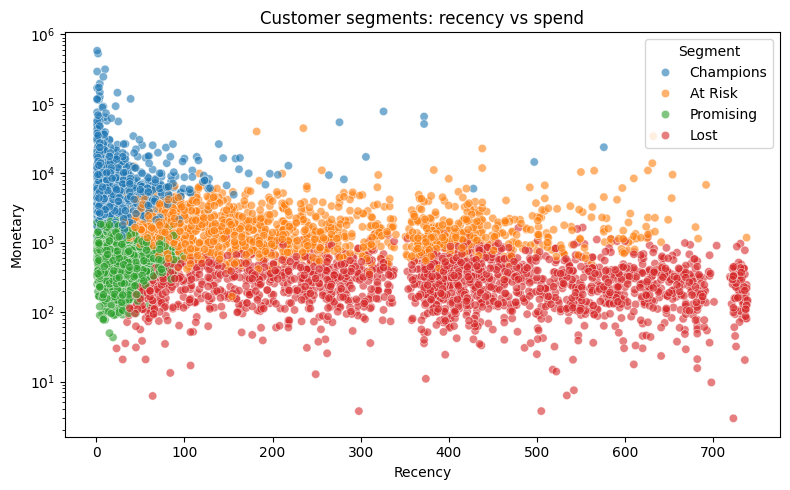

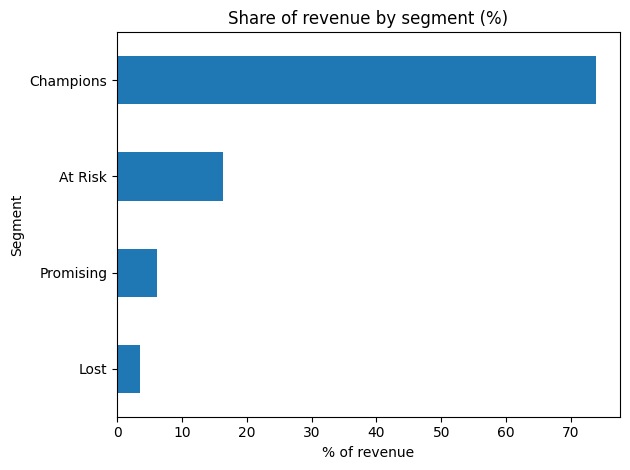

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Segment", alpha=0.6)
plt.yscale("log"); plt.title("Customer segments: recency vs spend")
plt.tight_layout(); plt.savefig("segments_scatter.png", dpi=200); plt.show()

share = rfm.groupby("Segment")["Monetary"].sum().sort_values()
(100 * share / share.sum()).plot(kind="barh", title="Share of revenue by segment (%)")
plt.xlabel("% of revenue"); plt.tight_layout()
plt.savefig("revenue_share.png", dpi=200); plt.show()

**Scatter Chart:**

 Champions sit at the top left (recent, high spend), Promising customers at the bottom left (recent, lower spend), At Risk customers in a band across the middle (older purchases, solid spend) and Lost customers at the bottom right (long inactive, low spend).

The segments overlap on this chart because it shows only two of the three RFM variables (Frequency is not shown), and the spend axis is on a log scale. The clustering uses all three together.

**Revenue-share Chart:**

 Champions bring in roughly **three-quarters of all revenue** from only a fifth of customers. At Risk customers contribute another 16%, which makes them the most valuable group to try to win back. Lost customers are a third of the customer base but only about 4% of revenue.

## 7. Recommended actions by segment

| Segment | Priority | Suggested action |
|---|---|---|
| Champions | Protect | Early access to new products, loyalty perks, a personal thank-you; watch for any drop in order frequency as an early warning |
| At Risk | Win back | A time-limited win-back offer or reminder email based on what they bought before; the highest-value group to re-activate |
| Promising | Grow | Cross-sell and bundle offers, a second-purchase incentive, and encouragement to buy more often |
| Lost | Low cost only | An inexpensive reactivation email or two, then stop spending on them |

**Why this order:** with 74% of revenue in one segment, retention comes first, then recovering At Risk customers, then growth.

## 8. Conclusions
- RFM and K-Means (K = 4) split 5,878 customers into **Champions, At Risk, Promising and Lost**.
- **About 20% of customers (Champions) generate about 74% of revenue**, so retention matters most.
- **At Risk** customers (25% of customers, 16% of revenue) average about £1,949 each, making them the best win-back target.
- Over a third of customers (**Lost**) are mostly one-time buyers who contribute under 4% of revenue.

**Limitations**
- The silhouette score (about 0.37) is moderate, so segments overlap and boundaries are not sharp.
- **23% of transaction rows had no Customer ID** and were excluded, so results cover identified customers only.
- The data covers 2009-2011 for one UK-based retailer, and some high spenders are likely business or wholesale buyers rather than individual shoppers.
- Segments reflect past behaviour and I did not test whether they predict future purchases.

**Next steps**
- Check whether segments predict future purchases by clustering on one period and tracking the next.
- Add product-category features or a churn-probability model.
- Compare with other clustering approaches such as hierarchical clustering or Gaussian mixtures.